In [10]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import umap.umap_ as umap
import seaborn as sns
import joblib
from gene_thesaurus import GeneThesaurus
from dotenv import load_dotenv

load_dotenv()

X_labeled_diagnostic_csv_path = os.getenv('X_LABELED_DIAGNOSTIC_CSV_PATH')
y_labeled_diagnostic_tsv_path = os.getenv('Y_LABELED_DIAGNOSTIC_TSV_PATH')
current_dir = os.getcwd()
color_palette_tsv_path = os.path.join(current_dir, '..', '..', 'reports', 'colors.tsv')
output_dir = os.getenv('OUTPUT_DIR')
n_jobs = int(os.getenv('N_JOBS', 1))
random_seed = int(os.getenv('RANDOM_SEED', 42))
selected_features_path = os.path.join(output_dir, "selected_features.pkl")
rf_model_path = os.getenv('RF_MODEL_PATH')
N_TOP_FEATURES = 500

print("Configuration:")
print(f"X_labeled_diagnostic_csv_path: {X_labeled_diagnostic_csv_path}")
print(f"y_labeled_diagnostic_tsv_path: {y_labeled_diagnostic_tsv_path}")
print(f"color_palette_tsv_path: {color_palette_tsv_path}")
print(f"output_dir: {output_dir}")
print(f"n_jobs: {n_jobs}")
print(f"random_seed: {random_seed}")
print(f"selected_features_path: {selected_features_path}")
print(f"rf_model_path: {rf_model_path}")
print(f"N_TOP_FEATURES: {N_TOP_FEATURES}")


Configuration:
X_labeled_diagnostic_csv_path: /home/mariya/Data/pallas/nf-core-gexml-output-labeled-diagnostic/transpose/transposed.csv
y_labeled_diagnostic_tsv_path: /home/mariya/Data/pallas/nf-core-gexml-output-labeled-diagnostic/class/subtypes.tsv
color_palette_tsv_path: /home/mariya/Development/pallas/training/gex/../../reports/colors.tsv
output_dir: /home/mariya/Data/pallas/training
n_jobs: 10
random_seed: 42
selected_features_path: /home/mariya/Data/pallas/training/selected_features.pkl
rf_model_path: /home/mariya/Data/pallas/training/final_model.pkl
N_TOP_FEATURES: 500


In [11]:
# Load selected features
selected_features = joblib.load(selected_features_path)
selected_features

Index(['ENSG00000000938', 'ENSG00000001036', 'ENSG00000001497',
       'ENSG00000001561', 'ENSG00000001617', 'ENSG00000002586',
       'ENSG00000002587', 'ENSG00000002745', 'ENSG00000002746',
       'ENSG00000003096',
       ...
       'ENSG00000284690', 'ENSG00000284713', 'ENSG00000284730',
       'ENSG00000284770', 'ENSG00000286237', 'ENSG00000288649',
       'ENSG00000288701', 'ENSG00000288722', 'ENSG00000290292',
       'ENSG00000291237'],
      dtype='object', length=3934)

In [12]:
# Load model
rf_model = joblib.load(rf_model_path)
rf_model.feature_importances_

array([2.48034101e-05, 6.36834514e-04, 3.82250994e-05, ...,
       1.03272815e-05, 8.24700172e-05, 3.63837044e-06], shape=(3934,))

In [13]:
# Join selected features and feature importances
feature_importances = pd.DataFrame({
    "feature": selected_features,
    "importance": rf_model.feature_importances_
})
feature_importances_ranked = feature_importances.sort_values(by="importance", ascending=False)
feature_importances_ranked

# Translate feature names to gene symbols
gt = GeneThesaurus(".")
translated = gt.translate_genes(feature_importances_ranked["feature"].tolist(),
                               source="ensembl_id", target="symbol")
feature_importances_ranked["gene_symbol"] = feature_importances_ranked["feature"].map(translated)
feature_importances_ranked

# Get top 100 features
top_features = feature_importances_ranked.head(N_TOP_FEATURES)
top_genes = top_features["feature"].tolist()
top_genes

['ENSG00000184507',
 'ENSG00000145794',
 'ENSG00000248329',
 'ENSG00000157985',
 'ENSG00000143995',
 'ENSG00000179241',
 'ENSG00000156298',
 'ENSG00000117519',
 'ENSG00000185630',
 'ENSG00000196208',
 'ENSG00000079102',
 'ENSG00000173482',
 'ENSG00000184185',
 'ENSG00000035720',
 'ENSG00000159217',
 'ENSG00000048052',
 'ENSG00000182670',
 'ENSG00000101115',
 'ENSG00000164330',
 'ENSG00000185046',
 'ENSG00000101230',
 'ENSG00000147364',
 'ENSG00000078399',
 'ENSG00000075420',
 'ENSG00000250366',
 'ENSG00000105642',
 'ENSG00000176595',
 'ENSG00000106278',
 'ENSG00000087495',
 'ENSG00000151729',
 'ENSG00000142188',
 'ENSG00000177455',
 'ENSG00000122025',
 'ENSG00000148655',
 'ENSG00000002745',
 'ENSG00000036448',
 'ENSG00000253293',
 'ENSG00000106665',
 'ENSG00000081189',
 'ENSG00000136213',
 'ENSG00000118946',
 'ENSG00000151502',
 'ENSG00000186187',
 'ENSG00000101197',
 'ENSG00000070759',
 'ENSG00000153208',
 'ENSG00000103449',
 'ENSG00000131686',
 'ENSG00000151474',
 'ENSG00000159147',


In [14]:

color_palette = pd.read_csv(color_palette_tsv_path, sep='\t', index_col=0, header=None).squeeze("columns").to_dict()
color_palette


{'AML, APL-PML::RARA': '#d70000',
 'AML, CBFA2T3::GLIS2': '#8a3dff',
 'AML, CBFB::MYH11': '#00a60c',
 'AML, CEBPAalt': '#00a2c2',
 'AML, DEK::NUP214': '#b2e300',
 'AML, ETV6-r': '#ff7dd2',
 'AML, KMT2A-r': '#71005d',
 'AML, NPM1alt': '#ffa220',
 'AML, NUP98-r': '#04009a',
 'AML, PICALM::MLLT10': '#20ffd2',
 'AML, RUNX1::RUNX1T1': '#7d3100',
 'AML, other': '#ae9eff',
 'B-ALL, BCR::ABL1': '#b26500',
 'B-ALL, BCR::ABL1-like': '#0069ae',
 'B-ALL, DUX4-r': '#ca00be',
 'B-ALL, ETV6::RUNX1': '#9ab245',
 'B-ALL, ETV6::RUNX1-like': '#450071',
 'B-ALL, HLF-r': '#004d00',
 'B-ALL, IKZF1 N159Y': '#e77569',
 'B-ALL, KMT2A-r': '#00b282',
 'B-ALL, MEF2D-r': '#ef047d',
 'B-ALL, MYC-r': '#ffeb69',
 'B-ALL, NUTM1-r': '#a2394d',
 'B-ALL, PAX5 P80R': '#ce65ff',
 'B-ALL, PAX5alt': '#4500ff',
 'B-ALL, TCF3::PBX1': '#00e7fb',
 'B-ALL, ZNF384-r': '#5986ff',
 'B-ALL, high hyperdiploid': '#04db61',
 'B-ALL, hypodiploid': '#aaffa2',
 'B-ALL, iAMP21': '#8a08b2',
 'B-ALL, other': '#657100',
 'T-ALL': '#550014',
 '

In [15]:
import pandas as pd
import numpy as np
import umap
import hdbscan
from sklearn.preprocessing import OneHotEncoder

def create_umap(X, y):
    reducer = umap.UMAP(n_neighbors=15,
                    min_dist=0.1,
                    n_components=2,
                    random_state=random_seed)

    embedding_umap = reducer.fit_transform(X)

    umap_df = pd.DataFrame(embedding_umap, columns=['UMAP1', 'UMAP2'], index=X.index)
    umap_df['label'] = y.loc[umap_df.index]
    return umap_df

def show_umap(umap_df, title, palette, legend_title='Subtype'):
    # Plot UMAP
    plt.figure(figsize=(10,10))
    sns.scatterplot(x='UMAP1',
                    y='UMAP2',
                    hue='label',
                    data=umap_df,
                    palette=palette,
                    s=50,
                    alpha=0.8)

    plt.title(title, fontsize=18)
    plt.legend(
        title=legend_title,
        bbox_to_anchor=(1.05, 1),
        loc='upper left',
        borderaxespad=0,
        prop={'size': 8}
    )
    plt.tight_layout()
    plt.show()

# Create new col "disease" that sets B-ALL, T-ALL, AML or Non-leukemic
def map_disease(subtype):
    if "B-ALL" in subtype:
        return "B-ALL"
    elif "T-ALL" in subtype:
        return "T-ALL"
    elif "AML" in subtype:
        return "AML"
    else:
        return "Non-leukemic"

In [16]:
# Read in X and y
X_labeled_diagnostic = pd.read_csv(X_labeled_diagnostic_csv_path, index_col=0)
y_labeled_diagnostic = pd.read_csv(y_labeled_diagnostic_tsv_path, sep='\t', index_col=0)


In [17]:

y_labeled_diagnostic["class"].values

array(['B-ALL, ETV6::RUNX1', 'B-ALL, ETV6::RUNX1', 'B-ALL, ETV6::RUNX1',
       ..., 'B-ALL, high hyperdiploid', 'B-ALL, high hyperdiploid',
       'B-ALL, high hyperdiploid'], shape=(3237,), dtype=object)

In [18]:
# Get just selected features
X_labeled_diagnostic = X_labeled_diagnostic[top_genes]
X_labeled_diagnostic

,ENSG00000184507,ENSG00000145794,ENSG00000248329,ENSG00000157985,ENSG00000143995,ENSG00000179241,ENSG00000156298,ENSG00000117519,ENSG00000185630,ENSG00000196208,...,ENSG00000206190,ENSG00000213316,ENSG00000177614,ENSG00000145014,ENSG00000012124,ENSG00000145506,ENSG00000019582,ENSG00000171604,ENSG00000196371,ENSG00000108405
id,,,,,,,,,,,,,,,,,,,,,
SJALL015946_D1,0.501399,-0.451598,-0.152840,1.490379,0.391020,0.415214,6.064781,4.481366,2.057057,0.269098,...,3.904133,0.666655,-1.235576,3.159156,8.718601,2.919125,11.421991,5.824422,3.932634,9.314025
SJALL015985_D1,-1.098935,-0.517131,-1.235576,0.306832,6.233283,2.674331,0.409752,4.407660,-0.833836,0.521708,...,1.415727,0.223067,-0.742621,4.356880,9.499018,0.046248,11.475942,8.918595,4.648140,8.138949
SJALL015988_D1,-1.235576,-0.567130,-1.235576,3.121029,0.045753,-0.787730,7.200798,4.313984,0.846974,-0.542982,...,3.328183,0.025698,-0.705698,3.663816,8.190077,0.984762,12.143371,3.821742,5.007615,8.165636
SJALL050885_D1,-1.235576,0.782359,-1.235576,2.905874,0.325771,0.583234,5.893555,4.799438,0.376014,0.889841,...,5.030206,1.006769,-0.107658,3.874985,8.670502,0.671135,11.335349,4.781510,5.108765,7.920475
SJAML001409_D2,-1.235576,1.025679,-1.235576,-1.235576,5.403262,2.667743,4.145259,-0.957550,-0.881191,-0.540911,...,5.119805,0.925822,0.187409,5.696626,5.089098,3.370793,12.020307,6.238080,6.481213,7.485196
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Case_92,-1.235576,-1.235576,-1.235576,5.240819,-0.229846,0.839719,6.265778,4.859744,-0.677804,3.520549,...,4.134743,2.122341,-1.235576,5.986610,7.796149,1.023685,11.767710,3.475214,6.261597,8.549645
Case_93,-1.235576,1.016354,-1.235576,2.435850,0.660124,0.280131,5.291202,4.427508,-0.050238,3.302864,...,3.125057,4.095367,-1.235576,4.189503,7.108352,-1.235576,11.621066,4.926493,7.642384,7.993980
Case_95,-1.235576,-1.235576,-1.235576,1.373786,1.074388,-0.001336,0.820767,4.695983,0.061031,-1.235576,...,2.494662,3.208375,-1.235576,3.543482,7.062107,-0.191179,10.092362,6.226204,9.355060,7.995232


In [19]:
umap_df = create_umap(X_labeled_diagnostic, y_labeled_diagnostic)

/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


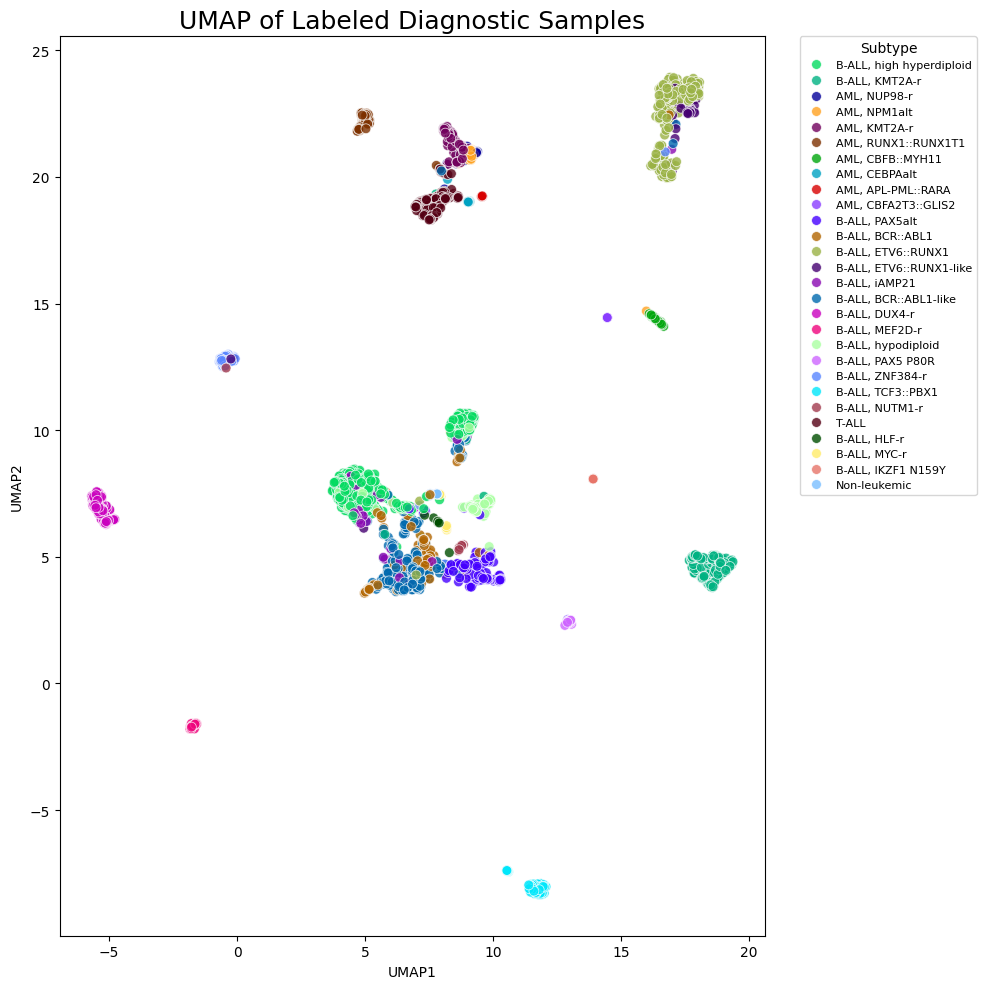

In [20]:
show_umap(umap_df, title='UMAP of Labeled Diagnostic Samples', palette=color_palette, legend_title='Subtype')